# Discussion Week 8: Social dimensions of Eaton and Palisades fires

In January 2025, the Eaton and Palisades fires burned thousands of homes in Los Angeles County. A wildfire’s impact depends not only on where it burns but also on who lives there: communities differ in their resources to evacuate, recover and rebuild. Here we will combine fire perimeters with the Environmental Justice Index to look at the social dimensions of these two fires. In this discussion section, you will:

- explore the EJI metadata and choose variables that could influence a community’s response to a wildfire
- spatially join census tracts with the fire perimeters
- clip census tracts to the fire perimeters and compare clipping with a spatial join
- make maps of the fire perimeters over a basemap
- compare an EJI variable across the two fire areas and discuss what the differences could mean for wildfire relief

## About the data

The Environmental Justice Index (EJI) is a national, place-based tool that measures the cumulative impacts of environmental burden on human health and health equity. It is produced by the Centers for Disease Control and Prevention (CDC) and the Agency for Toxic Substances and Disease Registry (ATSDR) [1].

The EJI ranks every census tract in the United States on 36 environmental, social and health factors, grouped into three modules:

- Social vulnerability: racial/ethnic minority status, socioeconomic status, household characteristics and housing type.
- Environmental burden: air pollution, potentially hazardous and toxic sites, built environment, transportation infrastructure and water pollution.
- Health vulnerability: pre-existing chronic disease burden.

The 2024 release also includes a separate climate burden module with indicators for extreme heat, wildfire and other extreme events. You can interactively explore this dataset through the EJI explorer.

The EJI download includes a data dictionary describing every variable. The first letters of each column name tell you what kind of value it holds:

- E_: estimates. For example, E_NOINT is the percentage of persons without internet in the census tract.
- EPL_: percentile ranks of those estimates, from 0 to 1. For example, EPL_NOINT is the tract’s percentile rank for E_NOINT.
- SPL_: summed ranks for domains, modules or the overall score. For example, SPL_EJI is the sum of the percentile ranks of the environmental burden, health vulnerability and social vulnerability modules (RPL_EBM, RPL_HVM and RPL_SVM).
- RPL_: percentile ranks for domains, modules or the overall score, from 0 to 1.

Values of -999 represent “no data”. The census tract boundaries come from the 2020 TIGER/Line Files.

The fire perimeters are polygons outlining the area burned by each fire. Different agencies publish perimeters for the Eaton and Palisades fires, and they may differ in how and when they were mapped. Read the metadata of the dataset you select so you know where its perimeters come from and how current they are.

## 1. Metadata Exploration

Open the data dictionary that came with your EJI download. Update the path to match your data directory:

In [45]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

In [2]:
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')

Take a first look at eji_dictionary on its own. What are its columns? What does each row describe?

In [ ]:
# Display rows and columns
print(eji_dictionary.shape)
# Display df head
eji_dictionary.head()

(170, 8)


,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (F...,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Bound...,No Value,No Value
3,AFFGEOID,AFFGEOID,Census tract identifier; a concatenation of cu...,No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a c...",No Value,No Value,No Value,2020 State FIPS + 2020 County FIPS + 2020 Cens...,Connecticut tracts are using updated 2022 Coun...


In the MODULE column, SVM stands for the social vulnerability module. Run the code below. Then:

- Have one person explain to the group what the code is doing.
- Add comments explaining what each line does.

In [ ]:
# Remove white space from the 2024 Variable Name column
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

# Set max column width
pd.set_option('display.max_colwidth', 120)

# Make list of columns variables that are in the SVM
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


With your team, select a few variables that, in your opinion, could influence a community’s response to a wildfire. You’ll be working with some of them in the following exercises. The EJI technical documentation describes each indicator: pages 40–41 list all the indicators, and pages 43–60 have a page for each indicator in the social vulnerability module, with its definition, data source and why it matters.

- E_POV200
- E_NOINT

## 2. Polygon intersection

Open the fire perimeters and the EJI data and do initial data exploration.

In [13]:
# Load fire perimeter data
fp = os.path.join('data','eaton_perimeter_20250121.geojson')
fire_Eaton = gpd.read_file(fp)

fp2 = os.path.join('data','palisades_perimeter_20250121.geojson')
fire_Palisades = gpd.read_file(fp2)

# Load EJI
fp3 = os.path.join('data','EJI_2024_California','EJI_2024_California.gdb')
eji = gpd.read_file(fp3)


In [14]:
fire_Eaton

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},1736294400000,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10094 34.16681, -118.10090 34.16680, -118.10087 34.16679, -118.10087 34.16677, -118.10084 34.16..."


In [15]:
fire_Palisades

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},1736208000000,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51975 34.02997, -118.51989 34.02991, -118.52002 34.02989, -118.52014 34.02993, -118.52025 34.03..."


Spatially join the EJI data with the Palisades fire perimeter using geopandas.sjoin() to get a geopandas.GeoDataFrame that will only have the census tracts intersecting the Palisades fire perimeter.

In [16]:
fire_Palisades.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
# Change crs
eji = eji.to_crs(fire_Palisades.crs)

In [24]:
# Join eji and palisades
eji_palisades = gpd.sjoin(eji,fire_Palisades, how = 'inner', predicate = 'intersects')
eji_palisades.head()

,OBJECTID_left,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,GEOID_2020,COUNTY,StateDesc,STATEABBR,...,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length
1328,6505,06,037,262706,140000US06037262706,06037262706,06037262706,Los Angeles County,California,CA,...,1,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614
1906,6501,06,037,262501,140000US06037262501,06037262501,06037262501,Los Angeles County,California,CA,...,1,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614
3768,5941,06,037,139802,140000US06037139802,06037139802,06037139802,Los Angeles County,California,CA,...,1,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614
3969,6506,06,037,262802,140000US06037262802,06037262802,06037262802,Los Angeles County,California,CA,...,1,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614
5594,5937,06,037,139703,140000US06037139703,06037139703,06037139703,Los Angeles County,California,CA,...,1,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614


<Axes: >

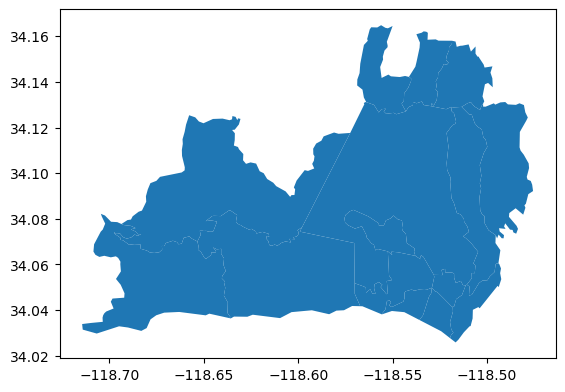

In [25]:
eji_palisades.plot()

In [29]:
# Join eji and eaton
eji_eaton = gpd.sjoin(eji,fire_Eaton, how  ='inner', predicate = 'intersects')
eji_eaton.head()

,OBJECTID_left,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,GEOID_2020,COUNTY,StateDesc,STATEABBR,...,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length
430,7051,06,037,461501,140000US06037461501,06037461501,06037461501,Los Angeles County,California,CA,...,1,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026
624,8038,06,037,930400,140000US06037930400,06037930400,06037930400,Los Angeles County,California,CA,...,1,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026
3605,7046,06,037,461000,140000US06037461000,06037461000,06037461000,Los Angeles County,California,CA,...,1,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026
3776,6969,06,037,430501,140000US06037430501,06037430501,06037430501,Los Angeles County,California,CA,...,1,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026
4512,7033,06,037,460001,140000US06037460001,06037460001,06037460001,Los Angeles County,California,CA,...,1,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026


<Axes: >

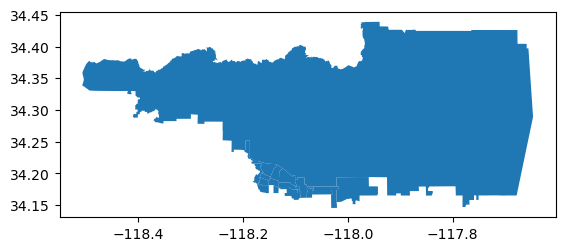

In [ ]:
eji_eaton.plot()

/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_69364/2728130352.py:18: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


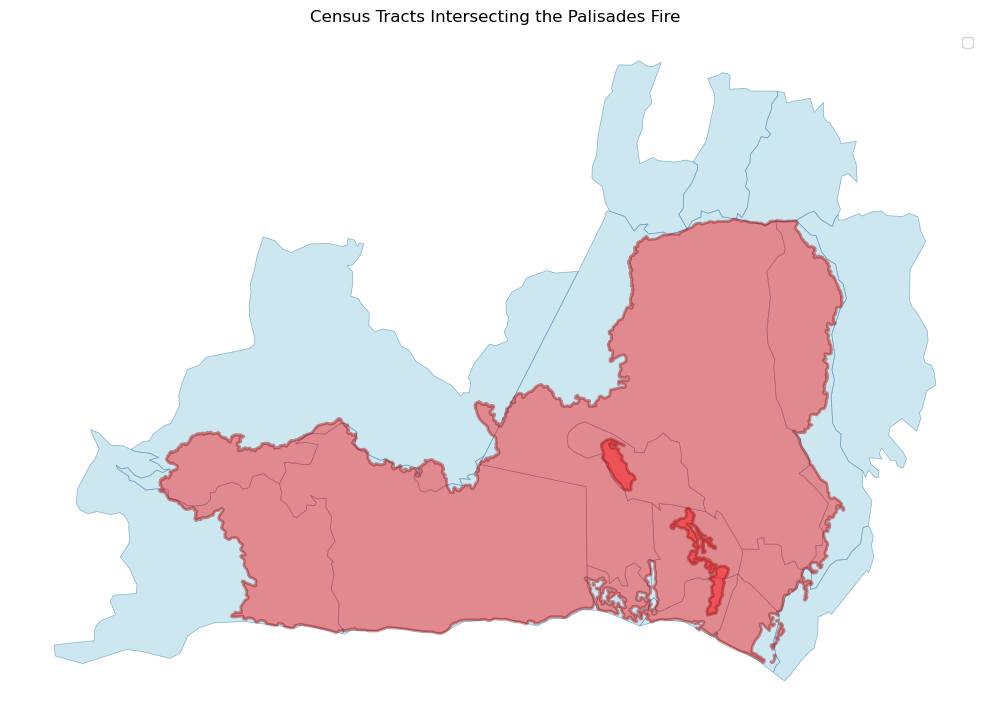

In [ ]:
# Create map - palisades
fig, ax = plt.subplots(1,1,figsize=(10,10))

eji_palisades.plot(ax = ax,
                   color = 'lightblue',
                   edgecolor='steelblue',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')
fire_Palisades.plot(ax=ax,
                    color='red',
                    alpha=0.4,
                    edgecolor='darkred',
                    linewidth=2,
                    label = 'Palisades perimeter')

ax.set_title('Census Tracts Intersecting the Palisades Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_69364/1137712174.py:18: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


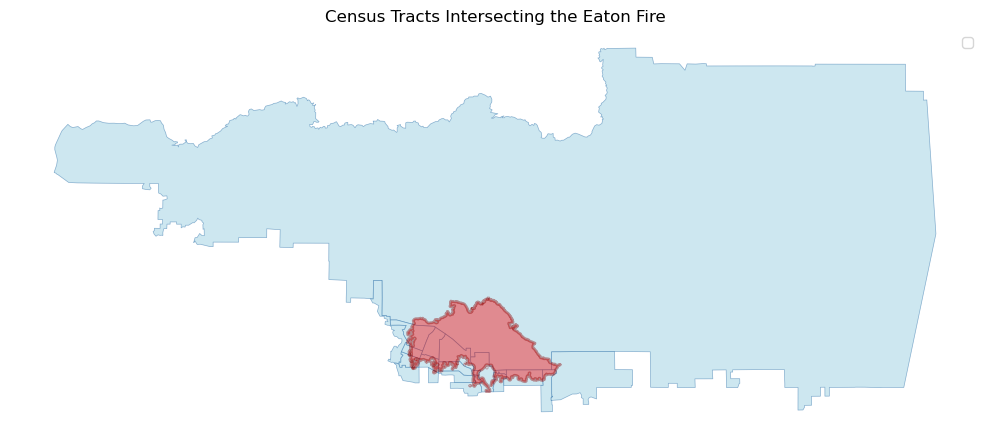

In [33]:
# Create map - eaton
fig, ax = plt.subplots(1,1,figsize=(10,10))

eji_eaton.plot(ax = ax,
                   color = 'lightblue',
                   edgecolor='steelblue',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')
fire_Eaton.plot(ax=ax,
                    color='red',
                    alpha=0.4,
                    edgecolor='darkred',
                    linewidth=2,
                    label = 'Eaton perimeter')

ax.set_title('Census Tracts Intersecting the Eaton Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

## Polygon Clipping

Clip the census tracts to the Palisades fire perimeter using geopandas.clip().

Do the same for the Eaton fire perimeter.
    
Visualize your data.

In [39]:
eji_palisades_clip = gpd.clip(eji_palisades,fire_Palisades)
eji_eaton_clip = gpd.clip(eji_eaton,fire_Eaton)


/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_69364/3662006507.py:12: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


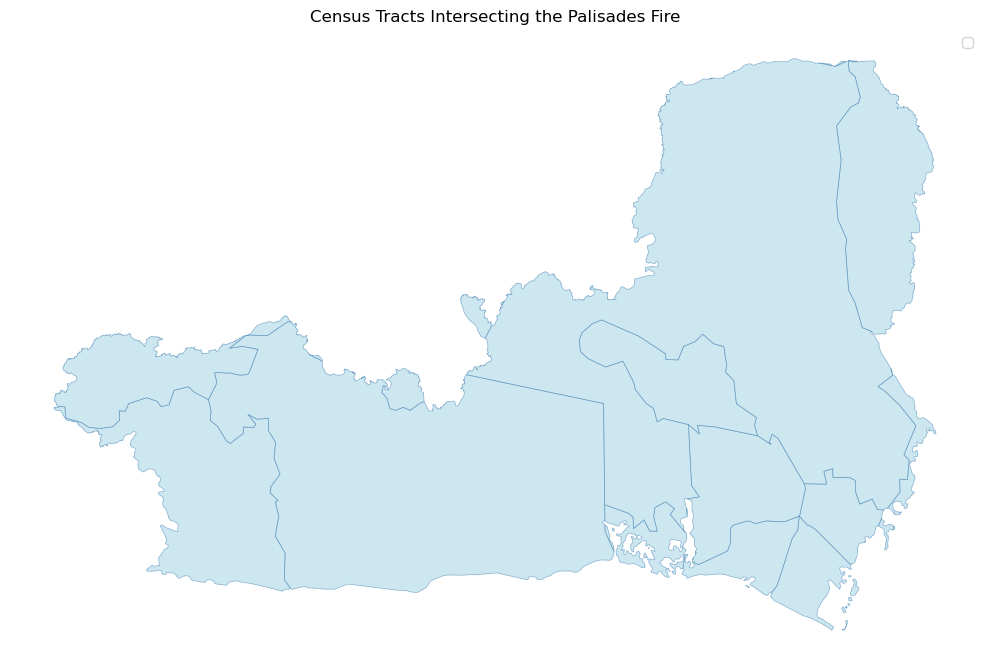

In [40]:
# Create map - palisades
fig, ax = plt.subplots(1,1,figsize=(10,10))

eji_palisades_clip.plot(ax = ax,
                   color = 'lightblue',
                   edgecolor='steelblue',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')

ax.set_title('Census Tracts Intersecting the Palisades Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_69364/1454663068.py:12: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


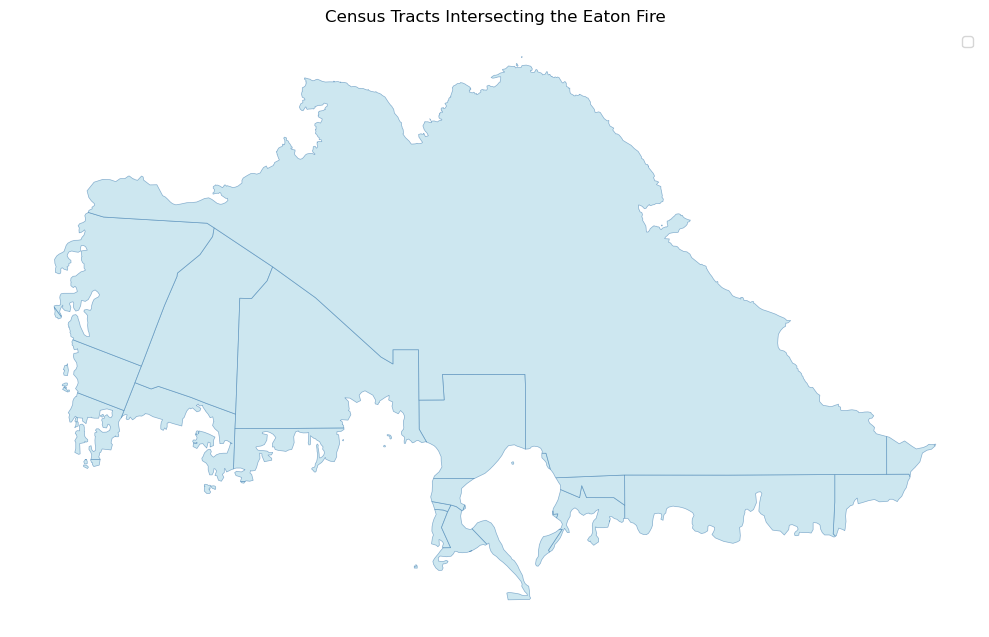

In [44]:
# Create map - palisades
fig, ax = plt.subplots(1,1,figsize=(10,10))

eji_eaton_clip.plot(ax = ax,
                   color = 'lightblue',
                   edgecolor='steelblue',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')

ax.set_title('Census Tracts Intersecting the Eaton Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Visualize Fire Perimeters with a Basemap

To add a basemap to our plot we will be using the contextily library.

Import the contextily library at the top of your notebook as ctx. This library is already installed in the EDS 220 environment.

Use and update the code below to plot the fire perimeters adding a basemap:

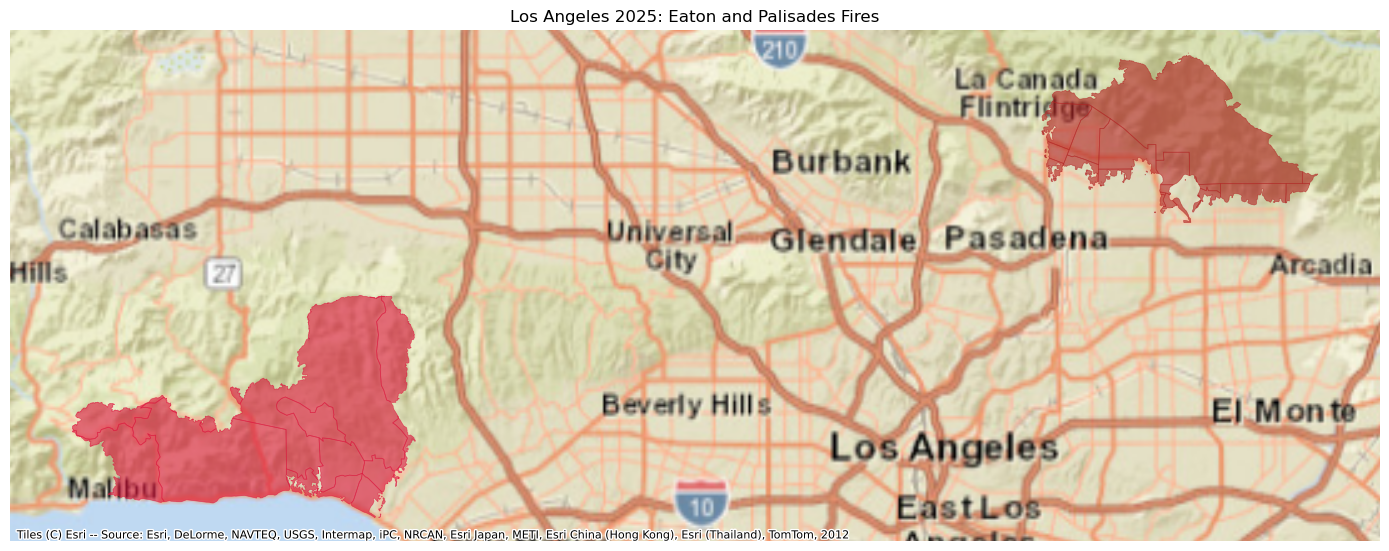

In [47]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR
eji_eaton_clip.plot(ax = ax,
                   color = 'firebrick',
                   edgecolor='firebrick',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')

eji_palisades_clip.plot(ax = ax,
                   color = 'crimson',
                   edgecolor='crimson',
                   linewidth=0.5,
                   alpha=0.6,
                   label='Census tracts')

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx.add_basemap(ax, crs=eji_palisades_clip.crs, source=ctx.providers.Esri.WorldStreetMap)

# ADD TITLE
ax.set_title('Los Angeles 2025: Eaton and Palisades Fires')

ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Visualize EJI Data

Decide whether you will use the census tracts from the spatial join (step 2) or from the clipping (step 3) for this map. Assign them to palisades_tracts and eaton_tracts, and write one sentence justifying your choice.

Use and update the code below to plot one of the variables you and your team explored in step 1 as being relevant to a community’s response to a wildfire.

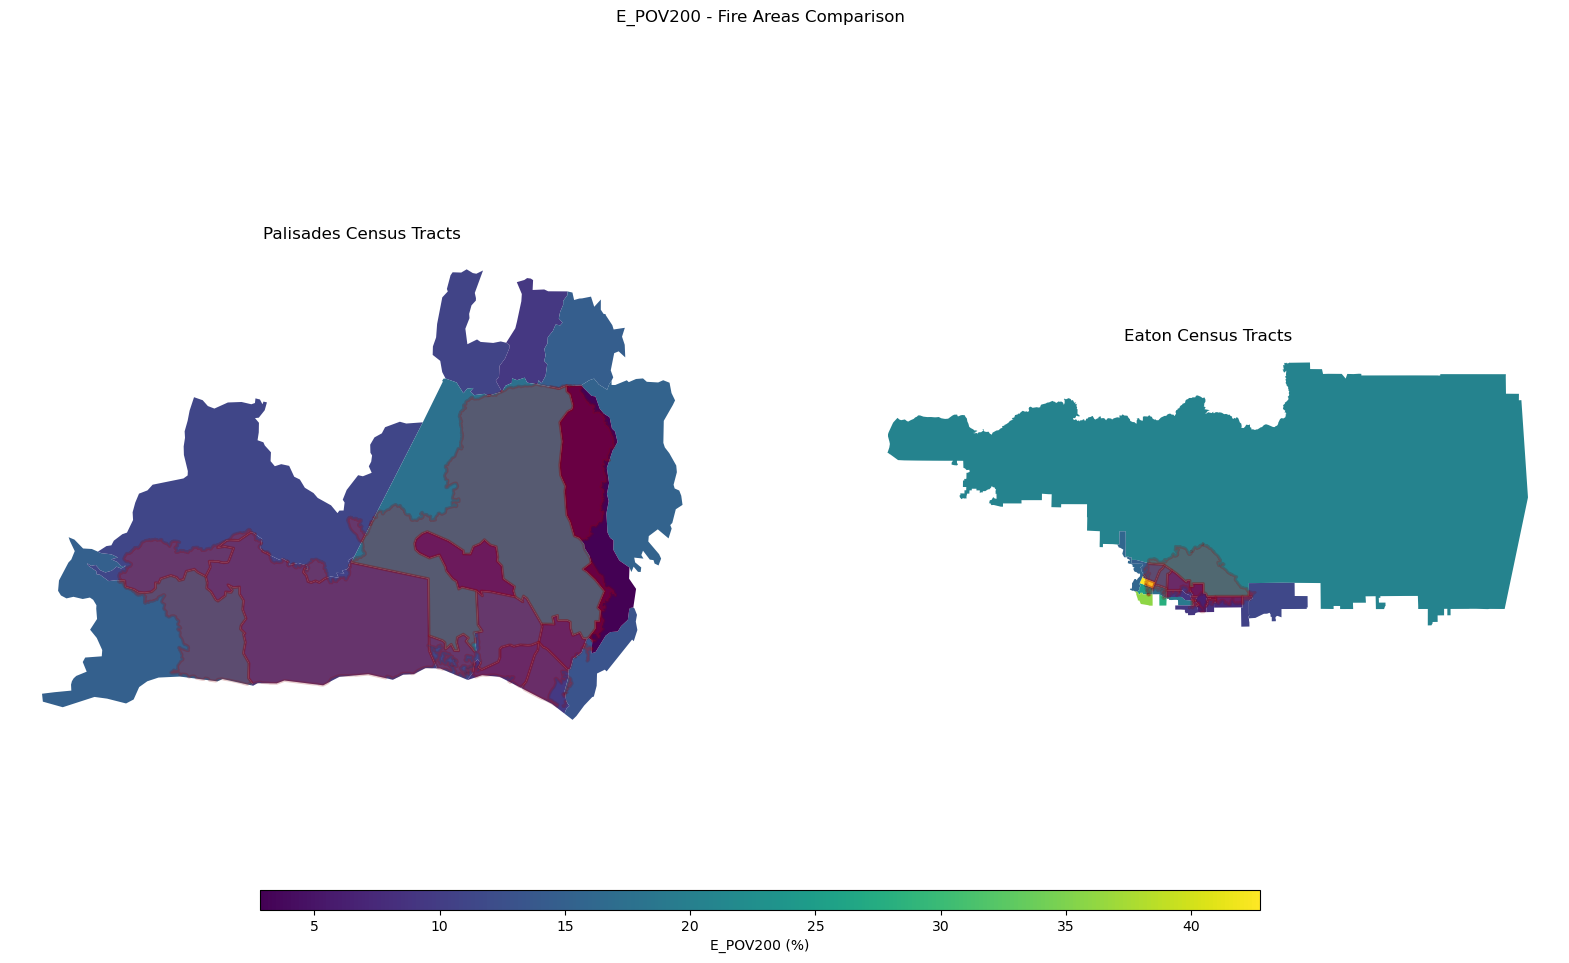

In [55]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

# UPDATE WITH YOUR EJI VARIABLE FROM STEP 1
eji_variable = 'E_POV200'

# Find common min/max for legend range
vmin = min(eji_palisades[eji_variable].min(), eji_eaton[eji_variable].min())
vmax = max(eji_palisades[eji_variable].max(), eji_eaton[eji_variable].max())

# Plot Palisades census tracts
eji_palisades.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax1,
)
eji_palisades_clip.plot(ax=ax1,
                    color='red',
                    alpha=0.2,
                    edgecolor='darkred',
                    linewidth=2,
                    label = 'Palisades perimeter')

ax1.set_title('Palisades Census Tracts')
ax1.axis('off')

# Plot Eaton census tracts
eji_eaton.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax2,
)
eji_eaton_clip.plot(ax=ax2,
                    color='red',
                    alpha=0.2,
                    edgecolor='darkred',
                    linewidth=2,
                    label = 'Eaton perimeter')

ax2.set_title('Eaton Census Tracts')
ax2.axis('off')

# Add overall title
fig.suptitle('E_POV200 - Fire Areas Comparison')

# Add shared colorbar at the bottom
sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('E_POV200 (%)')

plt.show()